# Responsible Web-Scale Data Curation – Results Notebook

This notebook presents the results of the integrated data curation pipeline using a 10,000-document Common Crawl WET dataset.

It evaluates document ingestion, deduplication, quality filtering, PII redaction, Toxic-BERT-based toxicity screening, language-wise removal patterns, and pipeline performance.

All reported pipeline metrics are based on actual execution results. Fairness observations are interpreted cautiously because manually verified toxicity labels, topic labels, and language-variety annotations are not available for the complete corpus.


# Responsible Web-Scale Data Curation
## Results and Fairness Evaluation

### Project Objective
To prepare a high-quality, privacy-aware and responsibly
filtered web-scale training corpus using distributed data
processing and automated content evaluation.

### Member 2 – Evaluation and Integration
This notebook evaluates the toxicity filtering component
and examines its potential impact across different topics
and language varieties.

### Evaluation Components
1. Toxicity detection and filtering.
2. Topic-wise removal analysis.
3. Language-variety fairness analysis.
4. False-positive and false-negative evaluation.
5. Responsible AI observations.

The notebook now uses actual execution results from the integrated Common Crawl curation pipeline. It includes measured document counts, Toxic-BERT screening results, language-wise descriptive analysis, and stage-wise execution times and throughput.

Topic-wise fairness analysis and manually labelled language-variety evaluation remain pending because the required validated annotations are not available in the current dataset.

In [19]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Load actual language-wise results
RESULTS_DIR = Path("results")

if not RESULTS_DIR.exists():
    RESULTS_DIR = Path("../results")

language_df = pd.read_csv(
    RESULTS_DIR / "language_fairness_actual.csv"
)

print("Actual Language-wise Fairness Results")
display(language_df)

print("\nTotal documents analysed:", language_df["input_documents"].sum())
print("Total documents flagged:", language_df["flagged_documents"].sum())
print("Total documents retained:", language_df["retained_documents"].sum())

Actual Language-wise Fairness Results


,language,input_documents,flagged_documents,retained_documents,removal_rate_percent,retention_rate_percent
0,af,3,0,3,0.00,100.00
1,bg,2,0,2,0.00,100.00
2,ca,20,0,20,0.00,100.00
3,cs,64,2,62,3.12,96.88
4,cy,3,0,3,0.00,100.00
5,da,52,1,51,1.92,98.08
6,de,462,6,456,1.30,98.70
7,en,3899,46,3853,1.18,98.82
8,es,473,1,472,0.21,99.79
9,et,23,3,20,13.04,86.96



Total documents analysed: 6996
Total documents flagged: 117
Total documents retained: 6879


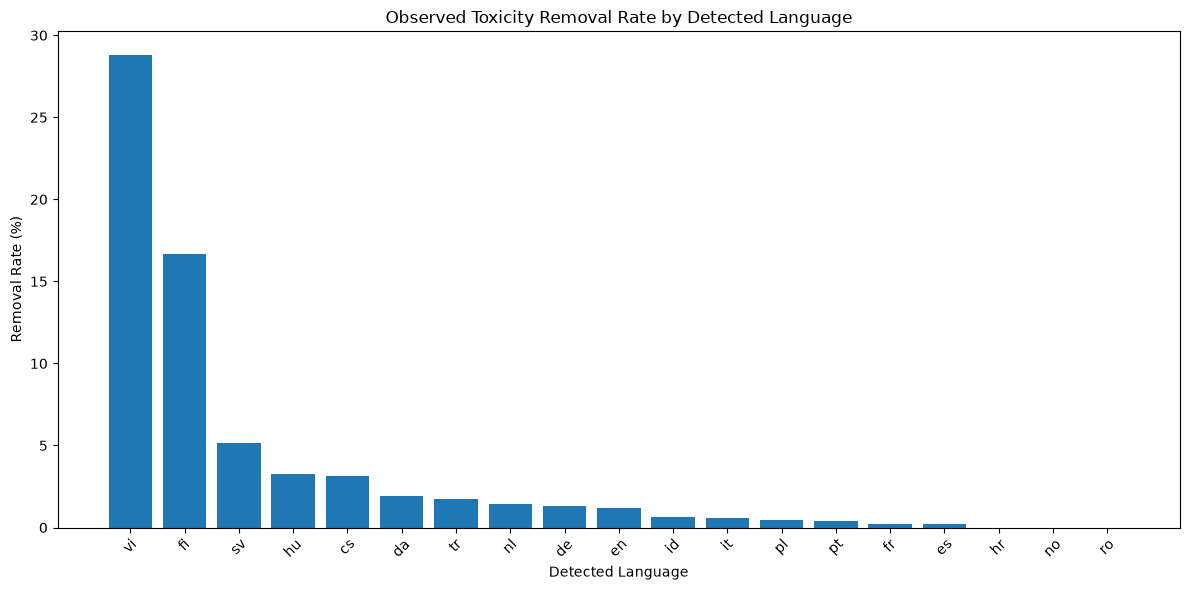

Languages included: 19
Minimum sample size per language: 30 documents


In [20]:

# Actual language-wise removal analysis
# Only languages with at least 30 documents are displayed.

language_plot = language_df[
    language_df["input_documents"] >= 30
].copy()

language_plot = language_plot.sort_values(
    "removal_rate_percent",
    ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    language_plot["language"],
    language_plot["removal_rate_percent"]
)

plt.title("Observed Toxicity Removal Rate by Detected Language")
plt.xlabel("Detected Language")
plt.ylabel("Removal Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Languages included:", len(language_plot))
print("Minimum sample size per language: 30 documents")

## Interpretation and Limitations

### Observations and Responsible AI Analysis

The pipeline processed 10,000 Common Crawl documents and retained 6,879 documents after deduplication, quality filtering, PII redaction, and toxicity screening.

- **Deduplication:** Removed 167 duplicate documents (1.67%) using exact content hashing.
- **Quality filtering:** Removed 2,837 documents (28.85%). The ASCII alphabetic-character rule contributed 2,467 removals and may disadvantage content written in non-Latin scripts.
- **PII redaction:** Detected email patterns in 2,046 documents and phone patterns in 1,206 documents. Documents were redacted rather than removed.
- **Toxicity filtering:** Toxic-BERT flagged 117 of 6,996 documents (1.67%), retaining 6,879 documents (98.33%).

### Language-wise Observations

Automatic language identification showed different observed toxicity-removal rates across detected languages. Vietnamese had a removal rate of 28.80% (36 of 125 documents), compared with 1.18% for English (46 of 3,899 documents).

These are descriptive observations, not proof of model bias. Language identification errors, differences in content distribution, and model performance across languages may influence the results. Groups with fewer than 30 documents were excluded from the chart.

### Performance Observations

Toxicity filtering was the computational bottleneck, taking approximately 3,019.96 seconds and processing 2.32 documents per second. The other pipeline stages completed considerably faster.

The measured stage execution times total approximately 3,065.67 seconds (51.08 minutes). These are recorded execution times, not a benchmark of scalability across different hardware configurations or dataset sizes.

### Limitations

- Toxicity predictions are screening signals, not verified ground-truth labels.
- No manually labelled full-corpus evaluation was available to calculate reliable false-positive and false-negative rates.
- Automatic language identification does not identify dialects or varieties such as Indian English.
- Topic-wise fairness evaluation remains pending because validated topic labels are unavailable.
- Regex-based PII detection cannot guarantee identification of every personal information pattern.
- Exact hashing detects exact duplicates, not semantic near-duplicates.
- The quality filter's ASCII-based rule may disadvantage non-Latin scripts.
- Results are based on a 10,000-document Common Crawl sample and should not be generalized to the entire web.

### Conclusion

The project demonstrates a distributed web-scale data curation workflow combining deduplication, quality filtering, PII redaction, and transformer-based toxicity screening. The actual results show that 6,879 of the original 10,000 documents were retained.

The evaluation also highlights responsible data curation concerns, particularly the potential impact of language-dependent quality rules and differences in observed toxicity-removal rates. Further manually labelled fairness evaluation and larger-scale performance testing are required before drawing stronger conclusions.

## 1. Stage-wise document counts
Add counts from Member 1's deduplication, quality, and PII logs, then add toxicity results. Use actual recorded counts only.

,stage,documents
0,Raw input,10000
1,After deduplication,9833
2,After quality filtering,6996
3,After PII redaction,6996
4,After toxicity filtering,6879


,stage,documents,documents_removed
0,Raw input,10000,0
1,After deduplication,9833,167
2,After quality filtering,6996,2837
3,After PII redaction,6996,0
4,After toxicity filtering,6879,117


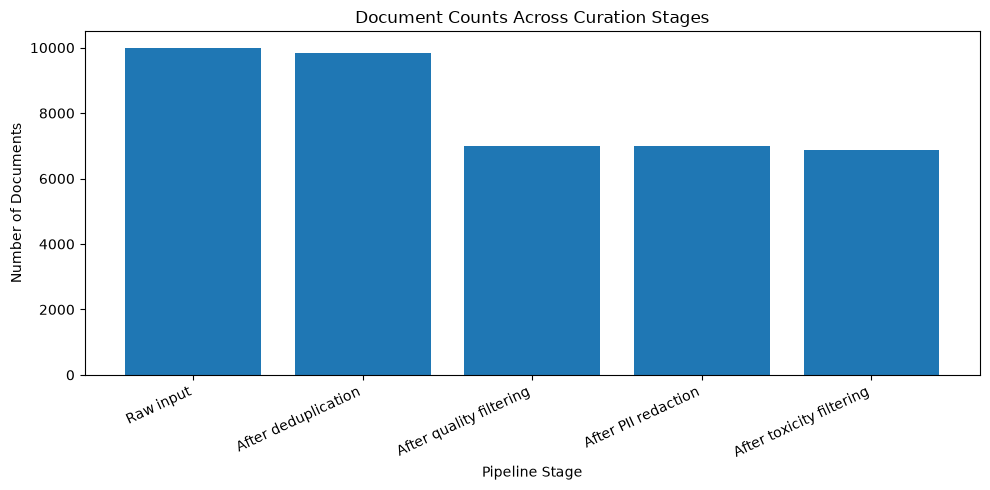

In [22]:
# Actual document counts recorded during pipeline execution

stage_counts = pd.DataFrame({
    "stage": [
        "Raw input",
        "After deduplication",
        "After quality filtering",
        "After PII redaction",
        "After toxicity filtering"
    ],
    "documents": [
        10000,
        9833,
        6996,
        6996,
        6879
    ]
})

display(stage_counts)

# Calculate total documents removed at each stage
stage_counts["documents_removed"] = (
    stage_counts["documents"].shift(1)
    - stage_counts["documents"]
).fillna(0).astype(int)

display(stage_counts)

plt.figure(figsize=(10, 5))
plt.bar(
    stage_counts["stage"],
    stage_counts["documents"]
)
plt.title("Document Counts Across Curation Stages")
plt.xlabel("Pipeline Stage")
plt.ylabel("Number of Documents")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 2. Toxicity filtering summary
Load the annotated output produced by `filter_records` or the integrated Spark stage.

,Metric,Value
0,Input documents,6996
1,Flagged as potentially toxic,117
2,Retained documents,6879
3,Removal rate,1.67%
4,Retention rate,98.33%
5,Mean toxicity score,0.04203
6,Threshold,0.5
7,Execution time (seconds),3019.96
8,Throughput (documents/second),2.32


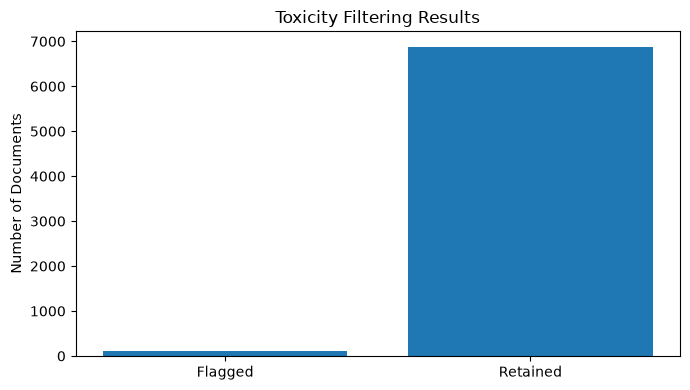

In [23]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = Path("../results")

toxicity = pd.read_csv(RESULTS_DIR / "toxicity_metrics.csv").iloc[0]

summary = pd.DataFrame({
    "Metric": [
        "Input documents",
        "Flagged as potentially toxic",
        "Retained documents",
        "Removal rate",
        "Retention rate",
        "Mean toxicity score",
        "Threshold",
        "Execution time (seconds)",
        "Throughput (documents/second)"
    ],
    "Value": [
        int(toxicity["input_documents"]),
        int(toxicity["flagged_documents"]),
        int(toxicity["retained_documents"]),
        f'{toxicity["removal_rate"] * 100:.2f}%',
        f'{toxicity["retention_rate"] * 100:.2f}%',
        f'{toxicity["mean_toxicity_score"]:.5f}',
        toxicity["threshold"],
        toxicity["execution_time_seconds"],
        toxicity["throughput_documents_per_second"]
    ]
})

display(summary)

plt.figure(figsize=(7, 4))
plt.bar(
    ["Flagged", "Retained"],
    [
        int(toxicity["flagged_documents"]),
        int(toxicity["retained_documents"])
    ]
)
plt.title("Toxicity Filtering Results")
plt.ylabel("Number of Documents")
plt.tight_layout()
plt.show()

## 3. Topic-wise fairness audit
Only run if a defensible topic label exists. Include group sizes and avoid interpreting tiny groups.

In [24]:
# Example after integration:
# topic_audit = (annotated.groupby(TOPIC_COLUMN)['retained']
#                .agg(input_documents='size', retained_documents='sum'))
# topic_audit['flagged_documents'] = topic_audit['input_documents'] - topic_audit['retained_documents']
# topic_audit['removal_rate'] = topic_audit['flagged_documents'] / topic_audit['input_documents']
# topic_audit.sort_values('removal_rate', ascending=False)

In [26]:
# Topic-wise fairness evaluation is pending.
# The current Common Crawl dataset does not contain validated topic labels.
# Assigning topics without a validated classification method could produce
# misleading fairness results.

print("Topic-wise fairness evaluation: Pending")
print("Reason: Validated topic labels are unavailable in the current dataset.")


Topic-wise fairness evaluation: Pending
Reason: Validated topic labels are unavailable in the current dataset.


## 4. Performance and scalability
Insert measured elapsed time, documents/second, dataset size, and hardware for each run. State whether model download/loading time is included.

,Stage,Documents processed,Execution time (seconds),Throughput (docs/sec)
0,Ingestion,10000,5.73,1745.99
1,Deduplication,10000,11.73,852.63
2,Quality filtering,9833,15.09,651.57
3,PII redaction,6996,12.56,556.89
4,Toxicity filtering,6996,3019.96,2.32


Total measured stage execution time: 3065.07 seconds
Total measured stage execution time: 51.08 minutes


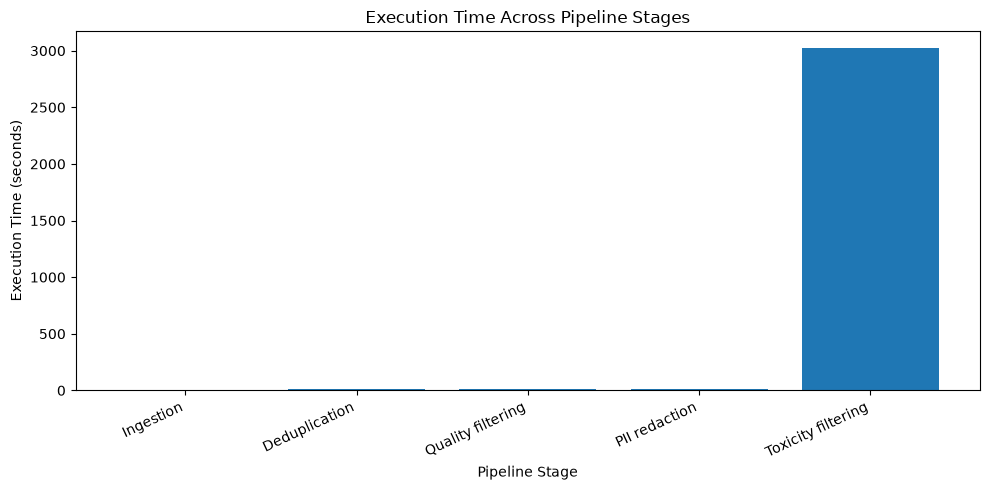

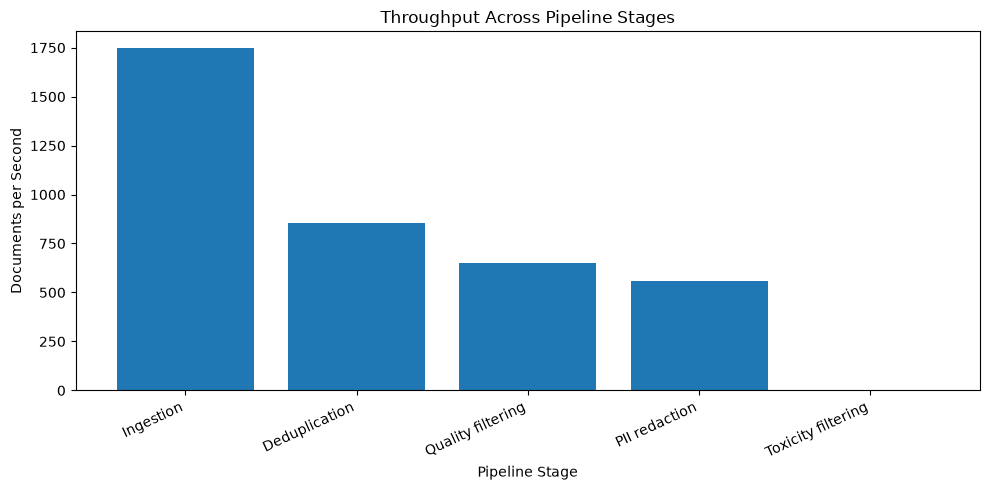

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# Measured execution times from actual pipeline runs
performance = pd.DataFrame({
    "Stage": [
        "Ingestion",
        "Deduplication",
        "Quality filtering",
        "PII redaction",
        "Toxicity filtering"
    ],
    "Documents processed": [
        10000, 10000, 9833, 6996, 6996
    ],
    "Execution time (seconds)": [
        5.7274, 11.7284, 15.0912, 12.5627, 3019.96
    ]
})

performance["Throughput (docs/sec)"] = (
    performance["Documents processed"] /
    performance["Execution time (seconds)"]
)

display(performance.round(2))

total_time = performance["Execution time (seconds)"].sum()

print(f"Total measured stage execution time: {total_time:.2f} seconds")
print(f"Total measured stage execution time: {total_time / 60:.2f} minutes")

# Execution time comparison
plt.figure(figsize=(10, 5))
plt.bar(
    performance["Stage"],
    performance["Execution time (seconds)"]
)
plt.title("Execution Time Across Pipeline Stages")
plt.xlabel("Pipeline Stage")
plt.ylabel("Execution Time (seconds)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# Throughput comparison
plt.figure(figsize=(10, 5))
plt.bar(
    performance["Stage"],
    performance["Throughput (docs/sec)"]
)
plt.title("Throughput Across Pipeline Stages")
plt.xlabel("Pipeline Stage")
plt.ylabel("Documents per Second")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()